<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/06_Android_Malware_Detection/QNN_AndroidMalware_Vyas2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classical vs quantum neural network for Android malware detection: Vyas, Lo and Zhang (2025) step by step

**Paper.** Arshiya Vyas, Dan Lo, Xinyue Zhang. *A Comparison of Classical and Quantum Neural Network Algorithms for Malware Detection.* 2025 ACM Southeast Conference (ACMSE 2025), Cape Girardeau, MO, USA, pp. 134-144. DOI: [10.1145/3696673.3723063](https://doi.org/10.1145/3696673.3723063).

**What this notebook does.** The paper builds two small neural networks for the same job, telling malicious Android apps from benign ones using only **10 binary features** of the public Drebin-based dataset of Yerima (15,036 apps): a classical Keras network and a 10-qubit quantum neural network (Qiskit `EstimatorQNN`, `ZZFeatureMap` + `RealAmplitudes`, 100 COBYLA iterations). It then asks four questions: (1) which 10 of the 215 features are best, (2) is the quantum network more accurate than the classical one (5 trials, two-sample t-test on F1), (3) does the classical network's runtime grow linearly with the number of samples, and (4) can the code be made readable for small businesses. This notebook re-runs (1), (2) and (3) on the **same public dataset**, shows every number next to the paper's, and discusses what can and cannot be concluded. Question (4) is a judgement by two professors and cannot be re-run.

**How to run.** Open in Google Colab (CPU runtime is enough), choose *Runtime -> Run all*. With `FAST_MODE = True` (default in this file; see the configuration cell) the whole notebook takes roughly 10 minutes; with `FAST_MODE = False` it uses the paper's budgets (500 samples, 5 trials, 100 epochs, 100 COBYLA iterations, sample sizes up to 10,000) and takes about an hour on a CPU.

**What you get at the end.** The dataset explained and plotted, the quantum circuit drawn, a feature-selection experiment, five classical and five quantum trials with confusion matrices, a t-test, a scalability study, the paper's figures redrawn, and a table that gives a verdict ("reproduced" / "not reached" / "exceeded" / "cannot be checked") for each claim.

**Data.** The Drebin-215 CSV from [figshare 5854653](https://figshare.com/articles/dataset/Android_malware_dataset_for_machine_learning_2/5854653) (the paper's reference [29]) is public and needs no account or token; it is downloaded inside the notebook. (No Hugging Face token is used.)

## The paper in one page

* **Problem.** Small businesses lack affordable malware detection. The authors want an open-source Colab tool and ask whether a *simulated* quantum neural network (QNN) is as accurate as a classical neural network (NN).
* **Decision.** Binary: malicious (`software_class = 1`, class `S` in the CSV) or benign (`0`, class `B`).
* **Data.** "Drebin-216" = the 215 binary Drebin-style features of Yerima's dataset (permissions, API calls, intents; 5,560 malware, 9,476 benign) plus the class column = 216 columns. Each feature is 1 if the app contains it.
* **Feature choice.** Only 10 features can be used (10 qubits). Three ways of choosing them are compared with the classical NN: the 10 columns with the highest absolute correlation with the class (`.corr`), the 10 most important features of a random forest, and simply the first 10 columns. Reported accuracies: **84 %**, **64 %**, **48 %** (Fig. 3), so the correlation set was used afterwards.
* **Models.** *Classical:* Keras `Sequential`, 3 layers, 500 samples (250 + 250), 75/25 train/test split, **100 epochs, batch 50**. *Quantum:* Qiskit `EstimatorQNN` from the authors' starter code (Dan Lo's GitHub tutorial), **10 qubits, 500 samples, 10 features scaled to [-1, 1], 100 iterations**, trained and scored on **all 500 samples** (no split).
* **Claims.**
  * (C1) Correlation-chosen features give the best accuracy (84 % vs 64 % vs 48 %).
  * (C2) Five trials each: classical F1 mean **0.6928** (sd 0.2055), quantum F1 mean **0.6406** (sd 0.1799) (Table 1); two-sample t-test **p = 0.6805 > 0.05**, so the means are statistically equal.
  * (C3) The classical NN trains in under 30 s; the simulated QNN needs about 30 min for 100 iterations.
  * (C4) Classical training runtime grows roughly linearly with the sample size (Table 2, Fig. 5, 150 epochs); accuracy 73-82 % except one outlier (57 % at 500) and does not rise from 1,000 to 10,000 samples.
  * (C5) Usability of the code was improved in two review iterations (qualitative, cannot be re-run).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | Drebin-216, Yerima figshare file | Same figshare file (`drebin-215-dataset-5560malware-9476-benign.csv`, 15,036 x 216). 5 rows with a `?` value are dropped; duplicates kept (the paper does not remove them) |
| Sampling | 500 random rows, 250 malware + 250 benign | Same, a fresh draw for each trial (`SEED + trial`) |
| Feature selection | `.corr`, random forest, first 10; apparently on the whole dataset | Done **on the training split of each trial only** (no leakage). The paper's list is also checked against the full-data ranking |
| Scaling | "scaled to [-1, 1]" with the starter code | Starter-code formula `2*(x-mean)/(max-min)`, mean/min/max fitted on the training data; used for both networks (`# CHOICE`) |
| Classical NN | Keras Sequential, 3 layers, 100 epochs, batch 50, 75/25 split | Dense 16-8-1 (ReLU, ReLU, sigmoid), Adam, binary cross-entropy (widths and optimiser not given, `# CHOICE`) |
| Quantum NN | `EstimatorQNN`, 10 qubits, starter code defaults, 100 iterations | `zz_feature_map(10, reps=2, entanglement="full")` + `real_amplitudes(10, reps=3)` (the library defaults the starter code relied on), observable Z on all qubits, COBYLA(maxiter=100) |
| QNN evaluation | Trained **and scored on all 500 samples** | **Protocol A** = exactly that. **Protocol B** = same 75/25 split as the classical NN (a fair held-out comparison, added here) |
| Simulator | Qiskit estimator on Colab (about 30 min) | Exact state-vector expectation values with a batched replica of the same circuit, asserted equal to the stock `EstimatorQNN` (see the circuit section below). Same maths, much faster |
| Trials | 5 | 5 (FAST_MODE: 3) |
| Test | Two-sample t-test, df = 8, alpha = 0.05 | `scipy.stats.ttest_ind` (pooled variance), plus Welch for reference |
| Scalability | 100 ... 10,000 samples, 150 epochs, first run only | Same sizes and epochs (FAST_MODE: up to 2,000 and 40 epochs), one run per size |
| Extras | none | Random forest and RBF-SVC baselines on the identical 10 inputs, confusion matrices, duplicate-leakage check |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and tensorflow.
# The pip line runs on Colab (or wherever qiskit-machine-learning is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning already present; skipping pip install.")

qiskit-machine-learning already present; skipping pip install.


In [2]:
# ---- Configuration: every tunable constant lives here -----------------------------------------
SEED = 42
FAST_MODE = False              # True: class demo (~10 min). False: the paper's budgets (~1 h on a CPU)

N_QUBITS = 10                  # paper: 10 features = 10 qubits
N_SAMPLES = 200 if FAST_MODE else 500          # paper: 500 (250 malware + 250 benign)
N_TRIALS = 3 if FAST_MODE else 5               # paper: 5 trials per network
TEST_SIZE = 0.25               # paper: 75/25 split for the classical NN
EPOCHS = 40 if FAST_MODE else 100              # paper: 100 epochs, batch size 50
BATCH_SIZE = 50
QNN_MAXITER = 25 if FAST_MODE else 100         # paper: 100 iterations of the estimator classifier (COBYLA)
SCALE_SIZES = [100, 200, 500, 1000, 2000] if FAST_MODE else [100, 200, 500, 1000, 2000, 5000, 10000]
SCALE_EPOCHS = 40 if FAST_MODE else 150        # paper: 150 epochs in the scalability test
DATA_DIR = "drebin_data"       # downloaded files are cached here
LOCAL_CSV = ""                 # optional: path of an uploaded copy of the Drebin-215 CSV
IBM_TOKEN = ""                 # not used: the paper only uses a simulator

In [3]:
import os, io, time, warnings, math
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display
warnings.filterwarnings("ignore")

import tensorflow as tf
from tensorflow import keras
tf.get_logger().setLevel("ERROR")
from scipy import stats
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.algorithms import NeuralNetworkClassifier
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
tf.keras.utils.set_random_seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)
print("tensorflow", tf.__version__, "| keras", keras.__version__, "| scikit-learn", sklearn.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__)
print("FAST_MODE =", FAST_MODE, "| N_SAMPLES =", N_SAMPLES, "| N_TRIALS =", N_TRIALS, "| EPOCHS =", EPOCHS, "| QNN_MAXITER =", QNN_MAXITER)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1
tensorflow 2.21.0 | keras 3.15.1 | scikit-learn 1.9.1
numpy 2.5.4 | pandas 3.0.6
FAST_MODE = False | N_SAMPLES = 500 | N_TRIALS = 5 | EPOCHS = 100 | QNN_MAXITER = 100


## 1. Getting the data

The authors used Yerima's *Android malware dataset for machine learning 2* (figshare, reference [29] of the paper): one row per Android app, 215 binary columns that say whether the app requests a given **permission**, calls a given **API method**, or listens for a given **intent**, and a last column `class` (`S` = malware, `B` = benign). The file is public; the cell below downloads it (two URLs are tried) and caches it in `DATA_DIR`. If both fail, upload the CSV to Colab and set `LOCAL_CSV`.

Cleaning follows the paper: nothing is removed except what cannot be used. One column (`TelephonyManager.getSimCountryIso`) contains the text `?` in five malware rows; these five rows are dropped. The thousands of rows that are exact duplicates of another row (the count is printed below) are **kept** because the paper does not remove them; the section on duplicates near the end measures how much that matters.

In [4]:
FIG_URLS = ["https://ndownloader.figshare.com/files/10391991", "https://figshare.com/ndownloader/files/10391991"]
CAT_URLS = ["https://ndownloader.figshare.com/files/10391994", "https://figshare.com/ndownloader/files/10391994"]

def fetch(urls, path, min_bytes, first_token):
    if os.path.exists(path) and os.path.getsize(path) >= min_bytes:
        return path
    last = None
    for u in urls:
        try:
            r = requests.get(u, stream=True, timeout=90)
            r.raise_for_status()
            buf = b"".join(r.iter_content(65536))
            if len(buf) >= min_bytes and buf[:60].decode("utf-8", "ignore").startswith(first_token):
                with open(path, "wb") as f:
                    f.write(buf)
                return path
            last = f"unexpected content from {u}"
        except Exception as e:
            last = f"{u}: {e}"
    raise RuntimeError("Could not download the dataset (" + str(last) + "). Upload the CSV and set LOCAL_CSV.")

csv_path = LOCAL_CSV or fetch(FIG_URLS, os.path.join(DATA_DIR, "drebin215.csv"), 1_000_000, "transact")
raw = pd.read_csv(csv_path, low_memory=False)
raw.columns = [c.strip() for c in raw.columns]
print("raw file:", raw.shape, "| file size %.1f MB" % (os.path.getsize(csv_path) / 1e6))

try:
    cat_path = fetch(CAT_URLS, os.path.join(DATA_DIR, "categories.csv"), 1000, "transact")
    categories = pd.read_csv(cat_path, header=None, names=["feature", "category"]).set_index("feature")["category"]
except Exception as e:
    categories = pd.Series(dtype=str); print("feature-category file not available:", e)

feat_cols = [c for c in raw.columns if c != "class"]
Xnum = raw[feat_cols].apply(pd.to_numeric, errors="coerce")
bad_rows = Xnum.isna().any(axis=1)
print("rows with a non-numeric value ('?'):", int(bad_rows.sum()), "-> dropped")
data = Xnum[~bad_rows].astype(float).copy()
data["y"] = (raw.loc[~bad_rows, "class"].astype(str).str.strip() == "S").astype(int).values   # 1 = malware (positive class)
data = data.reset_index(drop=True)
print("clean data:", data.shape, "| malware:", int(data.y.sum()), "| benign:", int((data.y == 0).sum()))
print("exact duplicate rows (features+class):", int(data.duplicated().sum()), "(kept, as in the paper)")
print("constant columns:", int((data[feat_cols].nunique() <= 1).sum()))

raw file: (15036, 216) | file size 6.5 MB


rows with a non-numeric value ('?'): 5 -> dropped


clean data: (15031, 216) | malware: 5555 | benign: 9476


exact duplicate rows (features+class): 7772 (kept, as in the paper)


constant columns: 0


## 2. The pipeline pieces (sampling, split, feature choice, scaling)

All the small functions used by the experiments are defined once here. Everything that learns from the data (correlations, forest importances, the scaling constants) is **fitted on the training split only**.

* `draw_balanced` takes `n` random rows, half malware and half benign (the paper found that balancing "drastically increased accuracy").
* `select_features` implements the paper's three ways of choosing 10 features.
* `Normaliser` is the starter-code scaling `2*(x - mean) / (max - min)`, fitted on training rows.

In [5]:
def draw_balanced(df, n, seed):
    r = np.random.default_rng(seed)
    n_mal = n // 2; n_ben = n - n_mal
    idx = np.concatenate([r.choice(df.index[df.y == 1], n_mal, replace=False),
                          r.choice(df.index[df.y == 0], n_ben, replace=False)])
    r.shuffle(idx)
    return df.loc[idx]

def select_features(Xtr, ytr, method, k=N_QUBITS, seed=SEED):
    if method == "corr":      # paper: highest absolute correlation with the class column
        c = Xtr.corrwith(pd.Series(ytr, index=Xtr.index)).abs().fillna(0.0)
        return list(c.sort_values(ascending=False, kind="mergesort").index[:k])
    if method == "rf":        # paper: RandomForestClassifier feature importances
        rf = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=-1).fit(Xtr, ytr)
        imp = pd.Series(rf.feature_importances_, index=Xtr.columns)
        return list(imp.sort_values(ascending=False, kind="mergesort").index[:k])
    if method == "first":     # paper: simply the first 10 columns
        return list(Xtr.columns[:k])
    raise ValueError(method)

class Normaliser:
    """Starter-code scaling 2*(x-mean)/(max-min), constants fitted on training rows only."""
    def fit(self, X):
        X = np.asarray(X, float)
        self.mean_ = X.mean(0); rg = X.max(0) - X.min(0); self.range_ = np.where(rg == 0, 1.0, rg)
        return self
    def transform(self, X):
        return 2.0 * (np.asarray(X, float) - self.mean_) / self.range_

def make_trial(trial, n=None):
    s = SEED + trial
    d = draw_balanced(data, n or N_SAMPLES, s)
    X, y = d[feat_cols], d.y.values
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=s)
    return dict(trial=trial, seed=s, X=X, y=y, Xtr=Xtr, Xte=Xte, ytr=ytr, yte=yte)

def prf(y, p):
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return dict(acc=accuracy_score(y, p), prec=precision_score(y, p, zero_division=0),
                rec=recall_score(y, p, zero_division=0), f1=f1_score(y, p, zero_division=0),
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

trials = [make_trial(t) for t in range(N_TRIALS)]
print("trial 0:", len(trials[0]["ytr"]), "train /", len(trials[0]["yte"]), "test rows;",
      "malware in train:", int(trials[0]["ytr"].sum()), "| in test:", int(trials[0]["yte"].sum()))

trial 0: 375 train / 125 test rows; malware in train: 188 | in test: 62


## Dataset Exploration and Visualisation

Before any model is trained, look at the real data. The tables and plots below use the actual rows of the Drebin-215 file: its shape, feature names, original labels, class balance, the kinds of features, and 2-D pictures of the apps coloured by their true label. The dataset only has the binary label (`S`/`B`); the malware family is not in this CSV, so there is no multiclass colouring to keep.

In [6]:
print("Dataset shape (rows, feature columns + label):", raw.shape, "| after cleaning:", data.shape)
print("Number of features:", len(feat_cols), "(each is 0/1: absent/present)")
print("First 15 feature names:", feat_cols[:15])
print("Last 5 feature names:  ", feat_cols[-5:])
print("\nOriginal label values in the CSV `class` column:", sorted(raw["class"].astype(str).str.strip().unique()), "(S = malware/'software_class 1', B = benign/0)")
counts = raw["class"].astype(str).str.strip().value_counts()
print(counts.to_string())
print("\nFraction of 1s per row (median, min, max):", float(data[feat_cols].mean(axis=1).median()),
      float(data[feat_cols].mean(axis=1).min()), float(data[feat_cols].mean(axis=1).max()))
if len(categories):
    print("\nFeature categories (figshare 'dataset-features-categories.csv'):")
    print(categories.value_counts().to_string())
display(data.iloc[:5, :10].assign(y=data.y.iloc[:5]))

Dataset shape (rows, feature columns + label): (15036, 216) | after cleaning: (15031, 216)
Number of features: 215 (each is 0/1: absent/present)
First 15 feature names: ['transact', 'onServiceConnected', 'bindService', 'attachInterface', 'ServiceConnection', 'android.os.Binder', 'SEND_SMS', 'Ljava.lang.Class.getCanonicalName', 'Ljava.lang.Class.getMethods', 'Ljava.lang.Class.cast', 'Ljava.net.URLDecoder', 'android.content.pm.Signature', 'android.telephony.SmsManager', 'READ_PHONE_STATE', 'getBinder']
Last 5 feature names:   ['WRITE_EXTERNAL_STORAGE', 'ACCESS_FINE_LOCATION', 'SET_WALLPAPER_HINTS', 'SET_PREFERRED_APPLICATIONS', 'WRITE_SECURE_SETTINGS']

Original label values in the CSV `class` column: ['B', 'S'] (S = malware/'software_class 1', B = benign/0)
class
B    9476
S    5560



Fraction of 1s per row (median, min, max):

 0.15348837209302327 0.0 0.5255813953488372

Feature categories (figshare 'dataset-features-categories.csv'):
category
Manifest Permission    113
API call signature      73
Intent                  23
Commands signature       6
B=Benign; S=Malware      1


,transact,onServiceConnected,bindService,attachInterface,ServiceConnection,android.os.Binder,SEND_SMS,Ljava.lang.Class.getCanonicalName,Ljava.lang.Class.getMethods,Ljava.lang.Class.cast,y
0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1
1,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1


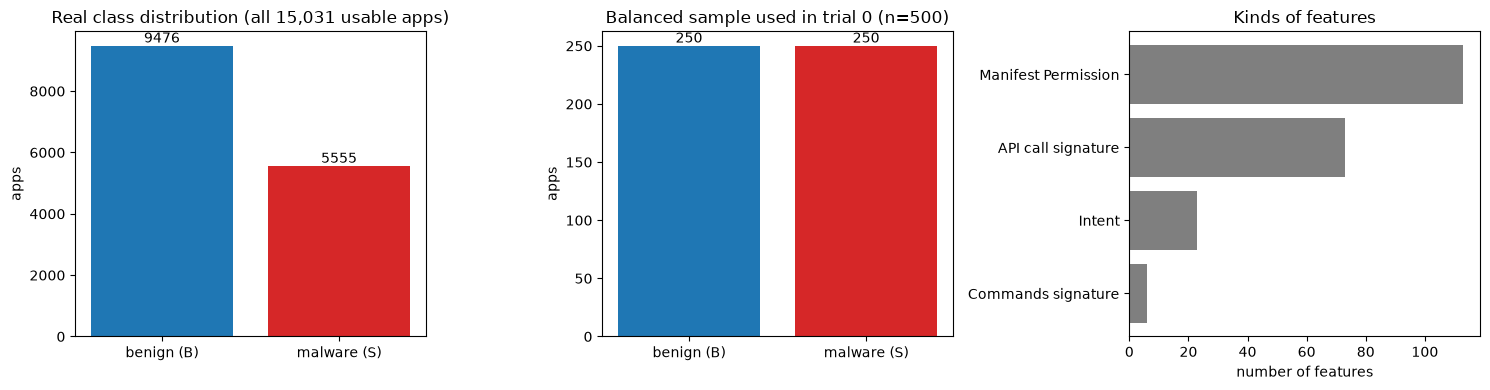

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cnt = data.y.map({0: "benign (B)", 1: "malware (S)"}).value_counts().reindex(["benign (B)", "malware (S)"])
axes[0].bar(cnt.index, cnt.values, color=["tab:blue", "tab:red"])
for i, v in enumerate(cnt.values): axes[0].text(i, v, str(v), ha="center", va="bottom")
axes[0].set_title("Real class distribution (all 15,031 usable apps)"); axes[0].set_ylabel("apps")

ct = data.y.groupby(data.y).size()
tr0 = trials[0]
c0 = pd.Series(tr0["y"]).map({0: "benign (B)", 1: "malware (S)"}).value_counts().reindex(["benign (B)", "malware (S)"])
axes[1].bar(c0.index, c0.values, color=["tab:blue", "tab:red"])
for i, v in enumerate(c0.values): axes[1].text(i, v, str(v), ha="center", va="bottom")
axes[1].set_title(f"Balanced sample used in trial 0 (n={len(tr0['y'])})"); axes[1].set_ylabel("apps")

if len(categories):
    cc = categories.reindex(feat_cols).fillna("unknown").value_counts()
    axes[2].barh(cc.index[::-1], cc.values[::-1], color="tab:gray")
    axes[2].set_title("Kinds of features"); axes[2].set_xlabel("number of features")
else:
    axes[2].axis("off")
plt.tight_layout(); plt.show()

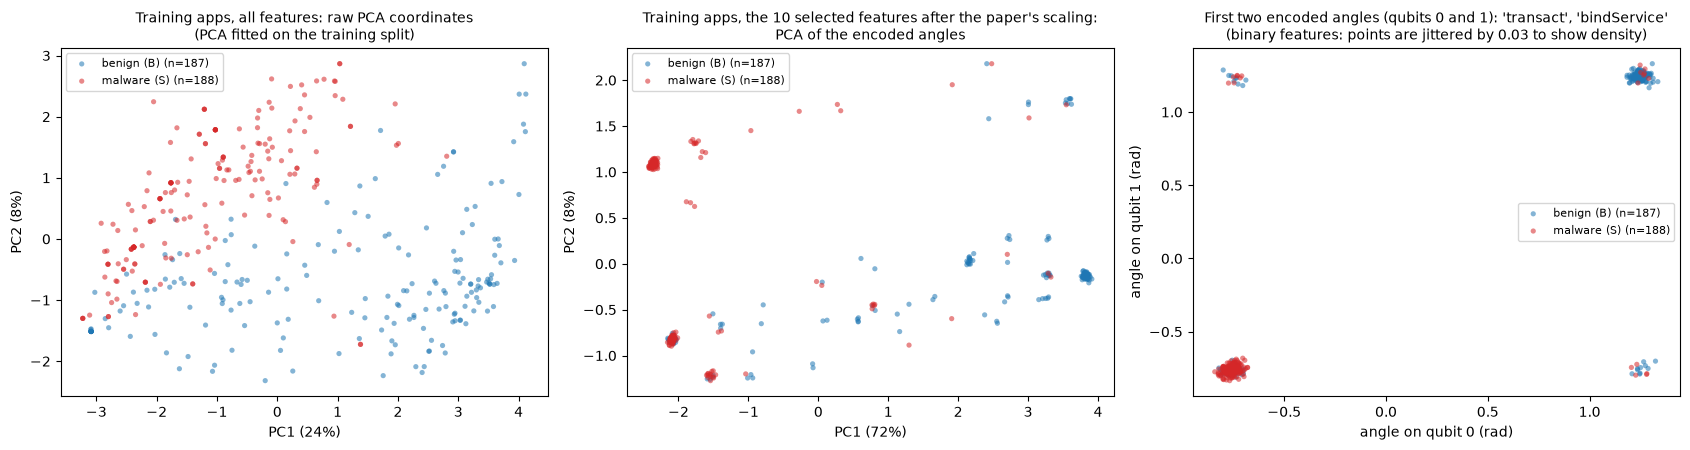

10 features selected by correlation on trial-0 training split: ['transact', 'bindService', 'ServiceConnection', 'attachInterface', 'onServiceConnected', 'android.os.Binder', 'Ljava.lang.Class.getCanonicalName', 'SEND_SMS', 'android.content.pm.Signature', 'Ljava.net.URLDecoder']


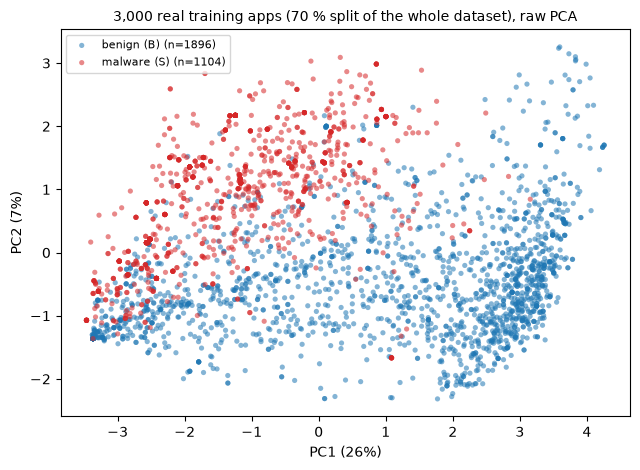

In [8]:
def scatter_by_class(ax, Z, y, title, xl, yl, jitter=0.0, seed=SEED):
    r = np.random.default_rng(seed)
    for lab, name, col in [(0, "benign (B)", "tab:blue"), (1, "malware (S)", "tab:red")]:
        m = y == lab
        pts = Z[m] + (r.normal(0, jitter, Z[m].shape) if jitter else 0)
        ax.scatter(pts[:, 0], pts[:, 1], s=14, alpha=0.55, c=col, label=f"{name} (n={m.sum()})", edgecolors="none")
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(fontsize=8)

# (a) all 214+ features: PCA fitted on the training split of trial 0 (real apps, true labels)
t0 = trials[0]
pca_all = PCA(n_components=2, random_state=SEED).fit(t0["Xtr"])
Ztr = pca_all.transform(t0["Xtr"])
# (b) the 10 features the QNN really uses, scaled as in the paper: PCA of the encoded rotation angles
f0 = select_features(t0["Xtr"], t0["ytr"], "corr")
nrm0 = Normaliser().fit(t0["Xtr"][f0])
A_tr = nrm0.transform(t0["Xtr"][f0])
pca_ang = PCA(n_components=2, random_state=SEED).fit(A_tr)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
scatter_by_class(axes[0], Ztr, t0["ytr"], "Training apps, all features: raw PCA coordinates\n(PCA fitted on the training split)",
                 f"PC1 ({pca_all.explained_variance_ratio_[0]:.0%})", f"PC2 ({pca_all.explained_variance_ratio_[1]:.0%})")
scatter_by_class(axes[1], pca_ang.transform(A_tr), t0["ytr"], "Training apps, the 10 selected features after the paper's scaling:\nPCA of the encoded angles",
                 f"PC1 ({pca_ang.explained_variance_ratio_[0]:.0%})", f"PC2 ({pca_ang.explained_variance_ratio_[1]:.0%})", jitter=0.03)
scatter_by_class(axes[2], A_tr[:, :2], t0["ytr"], f"First two encoded angles (qubits 0 and 1): '{f0[0]}', '{f0[1]}'\n(binary features: points are jittered by 0.03 to show density)",
                 "angle on qubit 0 (rad)", "angle on qubit 1 (rad)", jitter=0.03)
plt.tight_layout(); plt.show()
print("10 features selected by correlation on trial-0 training split:", f0)

# (c) a bigger picture: 70 % of all real apps, PCA fitted on that training part, 3,000 points drawn
Xa, ya = data[feat_cols], data.y.values
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=0.3, stratify=ya, random_state=SEED)
pca_big = PCA(n_components=2, random_state=SEED).fit(Xa_tr)
sel = np.random.default_rng(SEED).choice(len(Xa_tr), 3000, replace=False)
fig, ax = plt.subplots(figsize=(6.5, 4.8))
scatter_by_class(ax, pca_big.transform(Xa_tr.iloc[sel]), ya_tr[sel], "3,000 real training apps (70 % split of the whole dataset), raw PCA",
                 f"PC1 ({pca_big.explained_variance_ratio_[0]:.0%})", f"PC2 ({pca_big.explained_variance_ratio_[1]:.0%})")
plt.tight_layout(); plt.show()

**How to read these pictures.** Malware (red) and benign apps (blue) overlap strongly in the first two principal components of all 215 features, but are partly separable: the data are binary and many apps are identical on the selected features, so the same few combinations of 0/1 repeat (hence the jitter). Ten binary features can only describe at most 1,024 different apps, and that limit, not the classifier, caps the accuracy of both networks.

## 3. Sub-problem 1: which 10 features? (paper Section 7.1, Figs. 2 and 3)

First a check that does not involve a model: the paper lists the ten features with the highest absolute correlation with the class. Computing the same ranking on the full dataset should reproduce that list exactly, and also the forest and "first ten" lists. (This full-data ranking is used **only** to verify the paper's lists. The experiments below choose features from each trial's training split.)

corr           overlap with the paper's list: 10/10 | identical set: True
   ours only : [] 
   paper only: []
random forest  overlap with the paper's list: 6/10 | identical set: False
   ours only : ['Ljava.lang.Class.getCanonicalName', 'TelephonyManager.getDeviceId', 'android.telephony.SmsManager', 'attachInterface'] 
   paper only: ['CAMERA', 'TelephonyManager.getSimCountryIso', 'android.content.pm.Signature', 'bindService']
first ten      overlap with the paper's list: 10/10 | identical set: True
   ours only : [] 
   paper only: []

11th most correlated column: Ljava.lang.Class.getMethods (paper: Ljava.lang.Class.getMethods)


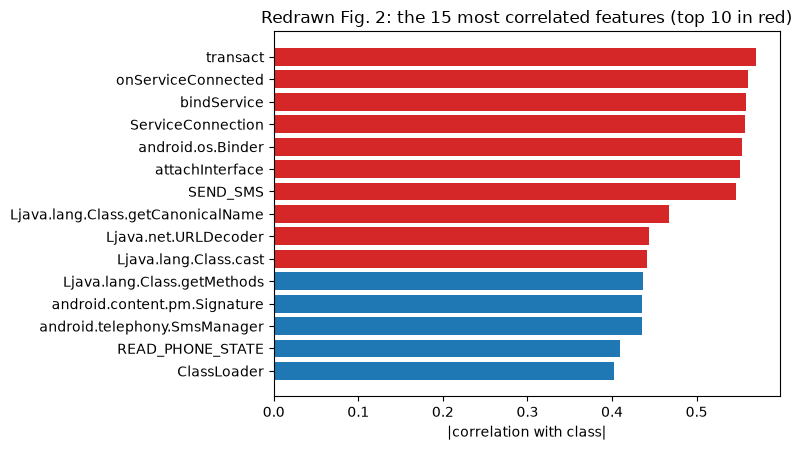

In [9]:
PAPER_CORR = ["transact", "onServiceConnected", "bindService", "ServiceConnection", "android.os.Binder", "attachInterface",
              "SEND_SMS", "Ljava.lang.Class.getCanonicalName", "Ljava.net.URLDecoder", "Ljava.lang.Class.cast"]
PAPER_RF = ["transact", "onServiceConnected", "bindService", "ServiceConnection", "android.os.Binder", "SEND_SMS",
            "android.content.pm.Signature", "READ_PHONE_STATE", "CAMERA", "TelephonyManager.getSimCountryIso"]
PAPER_FIRST = [c for c in PAPER_CORR if c != "Ljava.net.URLDecoder"] + ["Ljava.lang.Class.getMethods"]

Xf, yf = data[feat_cols], data.y.values
full_corr = Xf.corrwith(pd.Series(yf, index=Xf.index)).abs().sort_values(ascending=False)
FULL_CORR10 = list(full_corr.index[:10])
FULL_RF10 = select_features(Xf, yf, "rf")
FULL_FIRST10 = list(Xf.columns[:10])
for name, ours, theirs in [("corr", FULL_CORR10, PAPER_CORR), ("random forest", FULL_RF10, PAPER_RF), ("first ten", FULL_FIRST10, PAPER_FIRST)]:
    print(f"{name:14s} overlap with the paper's list: {len(set(ours) & set(theirs))}/10 | identical set: {set(ours) == set(theirs)}")
    print("   ours only :", sorted(set(ours) - set(theirs)), "\n   paper only:", sorted(set(theirs) - set(ours)))
print("\n11th most correlated column:", full_corr.index[10], "(paper: Ljava.lang.Class.getMethods)")

top15 = full_corr.head(15)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top15.index[::-1], top15.values[::-1], color=["tab:red" if i < 10 else "tab:blue" for i in range(15)][::-1])
ax.set_xlabel("|correlation with class|"); ax.set_title("Redrawn Fig. 2: the 15 most correlated features (top 10 in red)")
plt.tight_layout(); plt.show()

## 4. The classical neural network and the baselines

The classical network is a Keras `Sequential` model with three layers: two hidden `Dense` layers (16 and 8 ReLU units) and one sigmoid output unit, trained with Adam and binary cross-entropy for `EPOCHS` epochs at batch size 50. The paper does not give the widths or the optimiser, so these are `# CHOICE`s. A random forest and an RBF-SVC are trained on exactly the same scaled 10-feature inputs as honest baselines.

In [10]:
def classical_nn(Xtr, ytr, Xte, yte, epochs, seed, batch=BATCH_SIZE):
    tf.keras.utils.set_random_seed(seed)
    model = keras.Sequential([
        keras.layers.Input((Xtr.shape[1],)),
        keras.layers.Dense(16, activation="relu"),     # CHOICE: widths not given in the paper
        keras.layers.Dense(8, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])   # CHOICE: optimiser/loss not given
    t0 = time.time()
    hist = model.fit(Xtr, ytr, epochs=epochs, batch_size=batch, verbose=0)
    t_fit = time.time() - t0
    t0 = time.time()
    p = (model(Xte.astype("float32"), training=False).numpy().ravel() > 0.5).astype(int)
    return p, t_fit, time.time() - t0, hist.history["loss"]

def classical_pipeline(tr, fset, epochs=None):
    feats = select_features(tr["Xtr"], tr["ytr"], fset, seed=tr["seed"])
    nrm = Normaliser().fit(tr["Xtr"][feats])
    A_tr, A_te = nrm.transform(tr["Xtr"][feats]), nrm.transform(tr["Xte"][feats])
    p, t_fit, t_pred, loss = classical_nn(A_tr, tr["ytr"], A_te, tr["yte"], epochs or EPOCHS, tr["seed"])
    return feats, A_tr, A_te, p, t_fit, t_pred, loss

# Sub-problem 1: three feature sets, same trials, same split, same network
feat_rows, cache = [], {}
for tr in trials:
    for fset in ["corr", "rf", "first"]:
        feats, A_tr, A_te, p, t_fit, t_pred, loss = classical_pipeline(tr, fset)
        cache[(tr["trial"], fset)] = (feats, A_tr, A_te, p, t_fit, loss)
        feat_rows.append(dict(trial=tr["trial"], fset=fset, fit_s=t_fit, **prf(tr["yte"], p)))
feat_res = pd.DataFrame(feat_rows)
summary_feat = feat_res.groupby("fset").agg(acc_mean=("acc", "mean"), acc_std=("acc", "std"), f1_mean=("f1", "mean"), f1_std=("f1", "std")).reindex(["corr", "rf", "first"])
summary_feat["paper_acc"] = [0.84, 0.64, 0.48]
display(summary_feat.round(4))
print("Per-trial test accuracy:\n", feat_res.pivot(index="trial", columns="fset", values="acc").round(3).to_string())

,acc_mean,acc_std,f1_mean,f1_std,paper_acc
fset,,,,,
corr,0.8480,0.0435,0.8549,0.0340,0.84
rf,0.8592,0.0565,0.8547,0.0619,0.64
first,0.8192,0.0342,0.8339,0.0322,0.48


Per-trial test accuracy:
 fset    corr  first     rf
trial                     
0      0.848  0.840  0.912
1      0.856  0.776  0.816
2      0.792  0.816  0.928
3      0.832  0.800  0.808
4      0.912  0.864  0.832


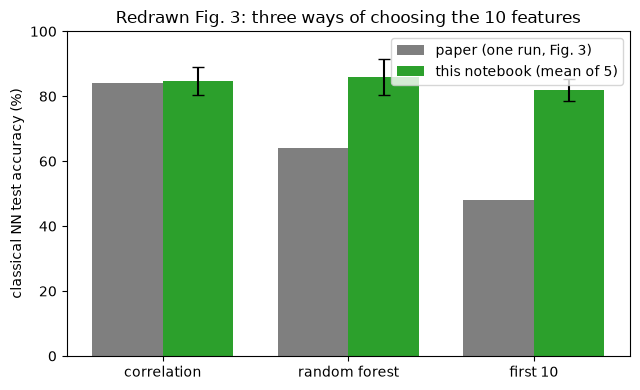

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 4))
xs = np.arange(3); w = 0.38
ax.bar(xs - w / 2, summary_feat["paper_acc"] * 100, w, label="paper (one run, Fig. 3)", color="tab:gray")
ax.bar(xs + w / 2, summary_feat["acc_mean"] * 100, w, yerr=summary_feat["acc_std"].fillna(0) * 100, capsize=4, label=f"this notebook (mean of {N_TRIALS})", color="tab:green")
ax.set_xticks(xs); ax.set_xticklabels(["correlation", "random forest", "first 10"]); ax.set_ylabel("classical NN test accuracy (%)")
ax.set_title("Redrawn Fig. 3: three ways of choosing the 10 features"); ax.legend(); ax.set_ylim(0, 100)
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The paper's quantum network is the Qiskit tutorial "Neural Network Classifier" circuit used in the authors' starter code (Dan Lo's `Predicting Tennis Matches` notebook): a **feature map** that writes the 10 scaled features into the angles of 10 qubits, followed by a trainable **ansatz**, read out through the expectation value of an observable:

* encoding: `zz_feature_map(10, reps=2, entanglement="full")` (Hadamards, single-qubit phase rotations, and ZZ-type phase interactions between all 45 qubit pairs, repeated twice). The paper only says "ZZFeatureMap"; these are the library defaults the starter code relied on. `# CHOICE`
* trainable part: `real_amplitudes(10, reps=3)` (four layers of RY rotations joined by three layers of CNOTs in the `reverse_linear` pattern) = 40 weights. `# CHOICE` (library default)
* read-out: expectation value of Z on all qubits (the `EstimatorQNN` default observable, a parity measurement), a number in [-1, 1]. Its sign is the class (`+1` malware, `-1` benign), as in the starter code. There are no measurement gates because the estimator computes the exact expectation value.
* training: `NeuralNetworkClassifier` + COBYLA, squared-error loss, 100 iterations (the paper's budget).

The figure is drawn from the very circuit object that is executed.

qubits: 10 | depth: 102 | size (gates): 377
input (data) parameters: 10 | trainable weights: 40
gate counts: {'cx': 207, 'p': 110, 'ry': 40, 'h': 20}


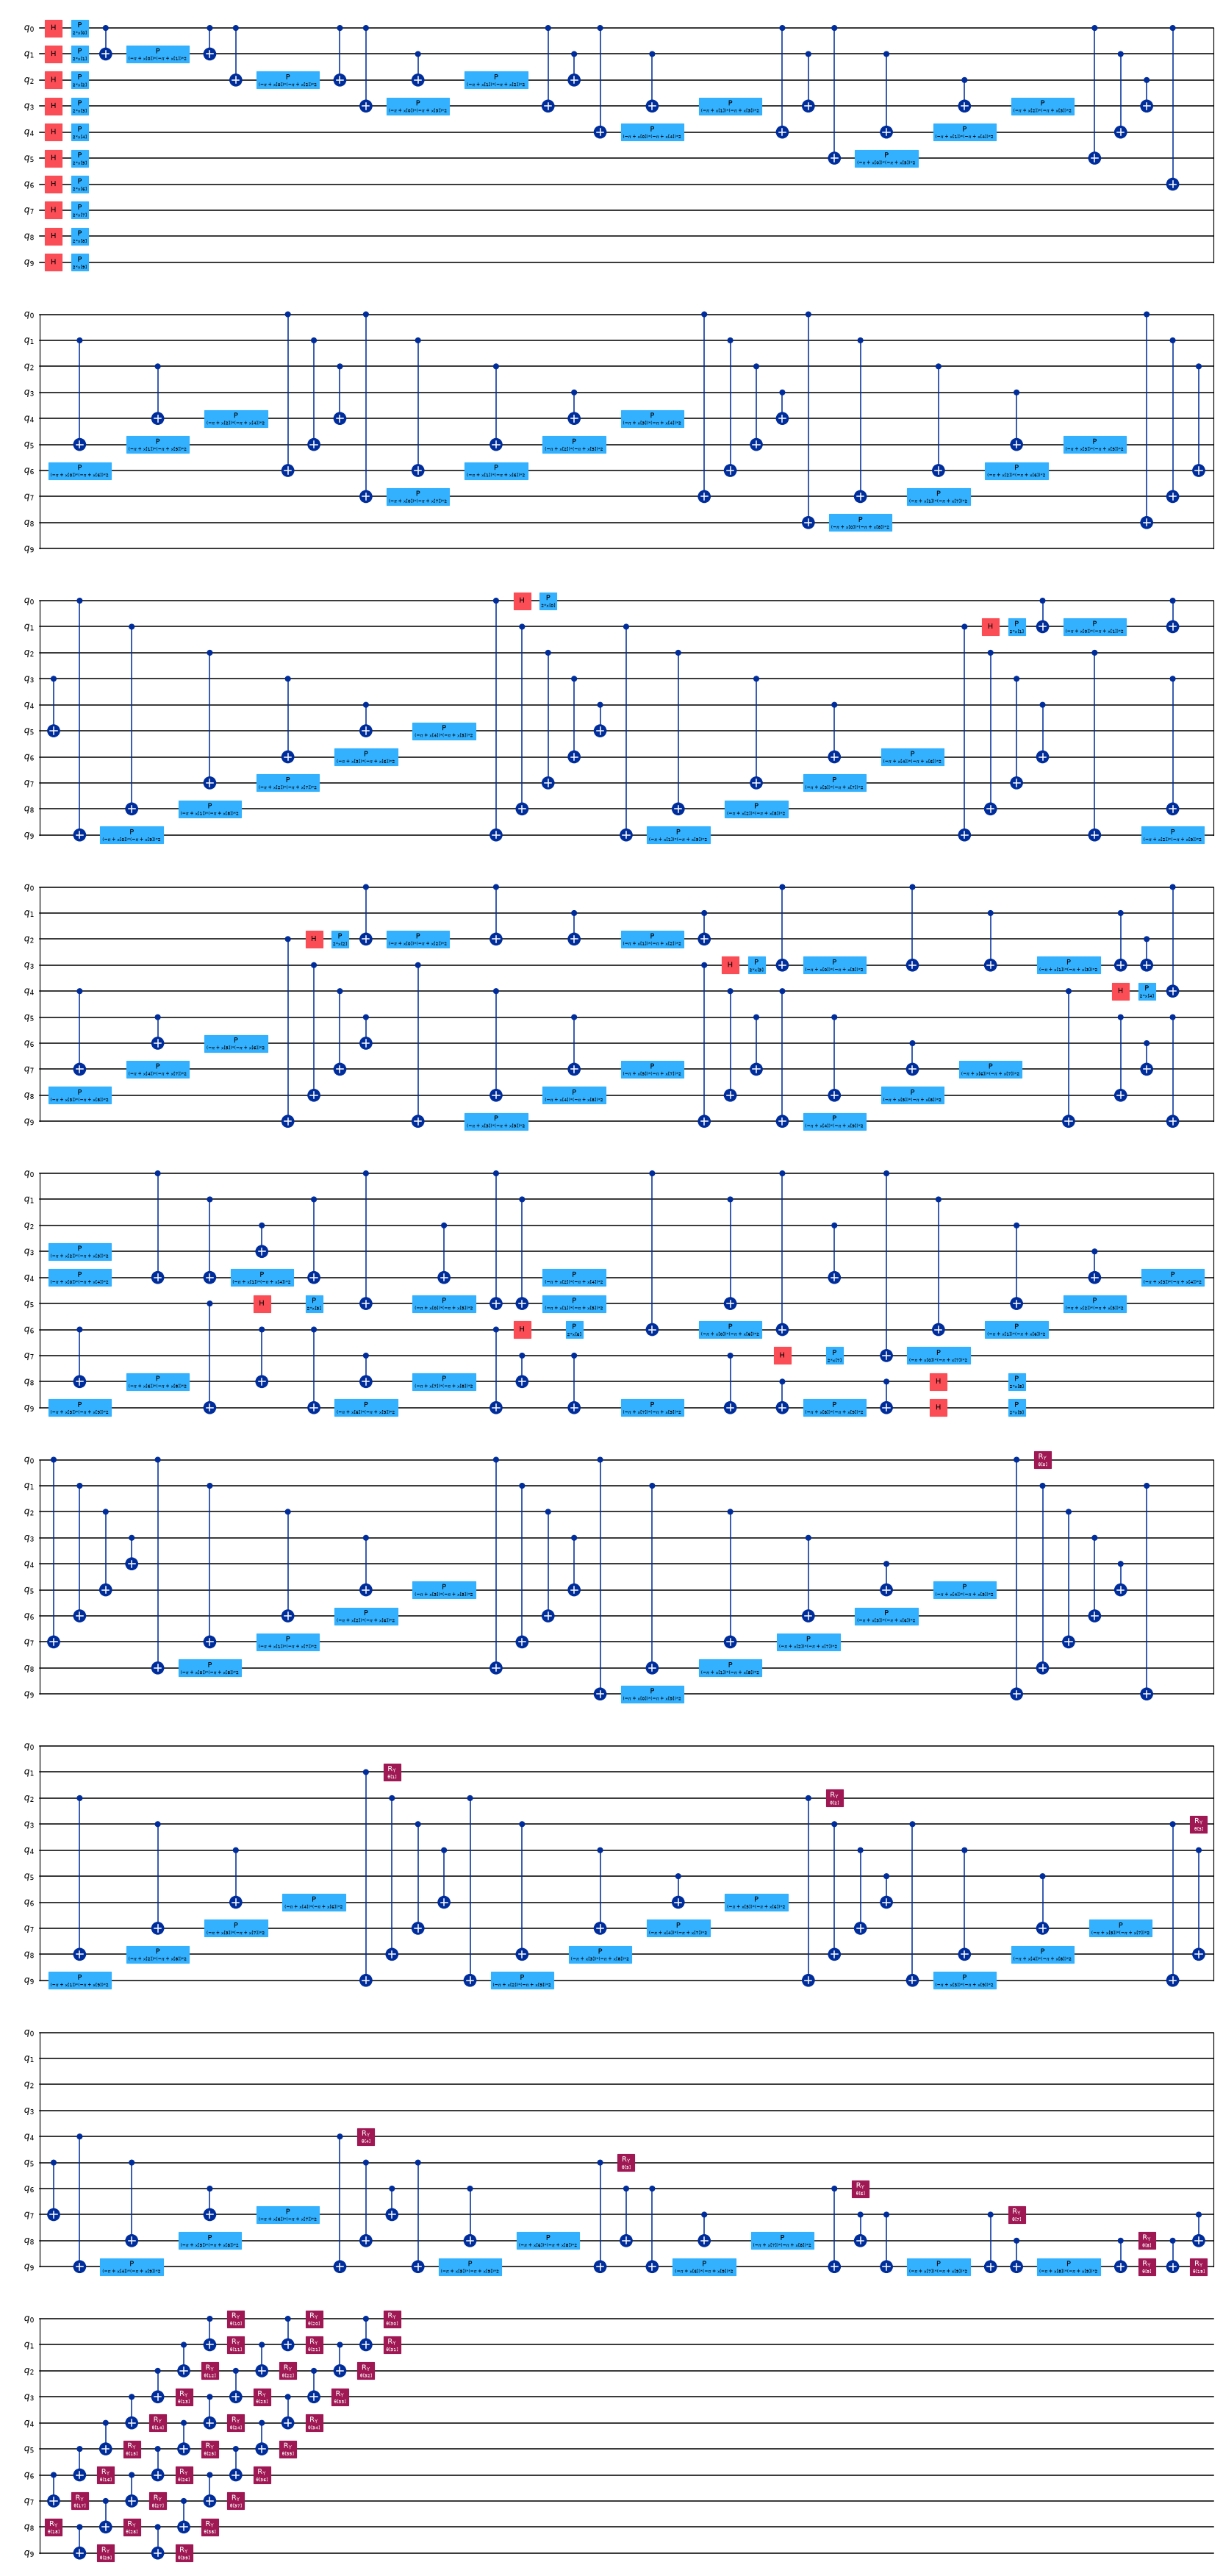

In [12]:
fm = zz_feature_map(N_QUBITS, reps=2, entanglement="full")     # CHOICE: library defaults of the starter code
an = real_amplitudes(N_QUBITS, reps=3)                         # CHOICE: library defaults of the starter code
qc = QuantumCircuit(N_QUBITS)
qc.compose(fm, inplace=True)
qc.compose(an, inplace=True)

print("qubits:", qc.num_qubits, "| depth:", qc.depth(), "| size (gates):", qc.size())
print("input (data) parameters:", fm.num_parameters, "| trainable weights:", an.num_parameters)
print("gate counts:", dict(qc.count_ops()))
fig = qc.draw("mpl", fold=45, scale=0.55)
display(fig); plt.close(fig)

### The same circuit, computed fast and checked

The stock `EstimatorQNN` evaluates every one of the 500 circuits separately and needs more than a minute for a single objective evaluation of COBYLA on this CPU (the paper reports about 30 minutes in total on Colab). Because the feature map depends only on the data and not on the weights, the exact same expectation value can be obtained much faster:

1. compute the state after the feature map for every sample once (Aer state-vector simulator, batched over samples),
2. for each new weight vector, push those states through the ansatz gate list (RY rotations and CNOTs, read from the `real_amplitudes` circuit itself) with plain NumPy,
3. average the Z-parity over the probabilities.

`FastEstimatorQNN` is a subclass of `EstimatorQNN` that does exactly this inside `_forward`; everything else (the `NeuralNetworkClassifier`, the optimiser, the loss) is untouched. The assertion below checks it against the unmodified `EstimatorQNN` on random inputs and weights. The numbers are exact expectation values, not shot estimates, so no sampling noise enters.

In [13]:
try:
    from qiskit_aer import AerSimulator
    _SIM = AerSimulator(method="statevector")
    _fm_save = fm.copy(); _fm_save.save_statevector()
    _FM_T = transpile(_fm_save, _SIM, optimization_level=0)
except Exception as e:
    print("Aer not available, falling back to Statevector loops:", e); _SIM = None

def feature_states(X):
    """State after the feature map for each row of X (shape B x 2^n)."""
    X = np.asarray(X, float)
    if _SIM is not None:
        res = _SIM.run(_FM_T, parameter_binds=[{p: X[:, i].tolist() for i, p in enumerate(fm.parameters)}]).result()
        return np.array([res.get_statevector(i) for i in range(len(X))])
    return np.array([Statevector(fm.assign_parameters(r)).data for r in X])

# ansatz as a gate list taken from the circuit that is actually executed
_flat = an.decompose()
_widx = {p: i for i, p in enumerate(an.parameters)}
_idx = np.arange(2 ** N_QUBITS)
_prog = []
for ins in _flat.data:
    q = [_flat.find_bit(b).index for b in ins.qubits]
    if ins.operation.name == "cx":
        perm = _idx.copy(); m = ((_idx >> q[0]) & 1) == 1; perm[m] = _idx[m] ^ (1 << q[1])
        if _prog and _prog[-1][0] == "perm": _prog[-1] = ("perm", _prog[-1][1][perm])
        else: _prog.append(("perm", perm))
    elif ins.operation.name == "r":                  # r(theta, pi/2) == RY(theta)
        assert abs(float(ins.operation.params[1]) - np.pi / 2) < 1e-12
        _prog.append(("ry", q[0], _widx[ins.operation.params[0]]))
    else:
        raise ValueError("unexpected gate " + ins.operation.name)
print("ansatz gate program:", sum(1 for s in _prog if s[0] == "ry"), "RY rotations and", sum(1 for s in _prog if s[0] == "perm"), "fused CNOT layers")

def apply_ansatz(S, w):
    B = S.shape[0]
    R = np.concatenate([S.real, S.imag], axis=0)      # the ansatz is real, so Re and Im parts evolve identically
    for st in _prog:
        if st[0] == "perm":
            R = R[:, st[1]]
        else:
            _, q, k = st; th = w[k] / 2; c, s = np.cos(th), np.sin(th)
            V = R.reshape(R.shape[0], 2 ** (N_QUBITS - 1 - q), 2, 2 ** q)
            a0, a1 = V[:, :, 0, :], V[:, :, 1, :]
            W = np.empty_like(V); W[:, :, 0, :] = c * a0 - s * a1; W[:, :, 1, :] = s * a0 + c * a1
            R = W.reshape(R.shape[0], -1)
    return R[:B] + 1j * R[B:]

Z_SIGNS = np.array([(-1) ** bin(k).count("1") for k in range(2 ** N_QUBITS)], float)   # eigenvalues of Z x ... x Z

class FastEstimatorQNN(EstimatorQNN):
    """EstimatorQNN with an exact, batched forward pass (same circuit, same observable)."""
    _ck = None; _cs = None
    def _forward(self, input_data, weights):
        X = np.asarray(input_data, float).reshape(-1, N_QUBITS)
        w = np.asarray(weights, float).ravel()
        key = (X.shape, hash(X.tobytes()))
        if key != self._ck:
            self._cs = feature_states(X); self._ck = key
        return ((np.abs(apply_ansatz(self._cs, w)) ** 2) @ Z_SIGNS).reshape(-1, 1)

stock = EstimatorQNN(circuit=qc, input_params=fm.parameters, weight_params=an.parameters)
fast = FastEstimatorQNN(circuit=qc, input_params=fm.parameters, weight_params=an.parameters)
chk = np.random.default_rng(SEED)
Xchk = chk.uniform(-1, 1, (3, N_QUBITS))
for _ in range(2):
    wchk = chk.uniform(0, 2 * np.pi, an.num_parameters)
    a, b = stock.forward(Xchk, wchk), fast.forward(Xchk, wchk)
    assert np.allclose(a, b, atol=1e-9), (a, b)
print("Equivalence check passed: FastEstimatorQNN == stock EstimatorQNN, max abs difference %.2e" % np.abs(a - b).max())
print("qubits:", fast.circuit.num_qubits, "| circuit depth:", fast.circuit.depth(), "| trainable parameters:", fast.num_weights,
      "| input parameters:", fast.num_inputs, "| observable:", stock._observables[0].paulis[0] if hasattr(stock._observables[0], "paulis") else stock._observables)

ansatz gate program: 40 RY rotations and 3 fused CNOT layers


Equivalence check passed: FastEstimatorQNN == stock EstimatorQNN, max abs difference 3.26e-16
qubits: 10 | circuit depth: 102 | trainable parameters: 40 | input parameters: 10 | observable: ZZZZZZZZZZ


## 5. Sub-problem 2: classical vs quantum, five trials each (paper Section 7.2, Table 1, Fig. 4)

For every trial a new random balanced sample of `N_SAMPLES` apps is drawn and:

* **classical NN**: 75 % train / 25 % test, F1 on the test rows (the 10 correlation features were chosen on the training rows);
* **quantum NN, protocol A (the paper's)**: features chosen and scaled on all `N_SAMPLES` rows, trained on all of them and scored on the same rows, i.e. a *training-set* score, exactly as described in Section 7.2.1 ("trained and tested on all samples");
* **quantum NN, protocol B (added here)**: trained on the same 75 % and scored on the same held-out 25 % as the classical network, the fair comparison;
* **random forest** and **RBF-SVC** on the same scaled inputs and split.

F1 is the harmonic mean of precision and recall with malware as the positive class (`2TP / (2TP + FP + FN)`), as in the paper.

In [14]:
def fit_qnn(A_fit, y_fit, A_eval, y_eval, maxiter, seed):
    algorithm_globals.random_seed = seed
    qnn = FastEstimatorQNN(circuit=qc, input_params=fm.parameters, weight_params=an.parameters)
    losses = []
    clf = NeuralNetworkClassifier(qnn, optimizer=COBYLA(maxiter=maxiter), callback=lambda w, f: losses.append(float(f)))
    t0 = time.time()
    clf.fit(A_fit, 2 * y_fit - 1)                       # labels in {-1, +1} as in the starter code
    t_fit = time.time() - t0
    p = (np.ravel(clf.predict(A_eval)) > 0).astype(int)
    return p, t_fit, losses

rows, loss_curves = [], {}
def add(model, tr, y, p, t):
    rows.append(dict(trial=tr["trial"], model=model, fit_s=t, **prf(y, p)))

for tr in trials:
    t_start = time.time()
    feats, A_tr, A_te, p_nn, t_nn, loss_nn = cache[(tr["trial"], "corr")]
    add("Classical NN (held-out 25%)", tr, tr["yte"], p_nn, t_nn)
    # baselines on the identical scaled inputs
    rf = RandomForestClassifier(n_estimators=100, random_state=tr["seed"], n_jobs=-1).fit(A_tr, tr["ytr"])
    add("Random forest (held-out 25%)", tr, tr["yte"], rf.predict(A_te), 0.0)
    sv = SVC(kernel="rbf", C=1.0, random_state=tr["seed"]).fit(A_tr, tr["ytr"])
    add("SVC rbf (held-out 25%)", tr, tr["yte"], sv.predict(A_te), 0.0)
    rf_all = RandomForestClassifier(n_estimators=100, random_state=tr["seed"], n_jobs=-1).fit(tr["Xtr"], tr["ytr"])
    add("Random forest, all 215 features (reference)", tr, tr["yte"], rf_all.predict(tr["Xte"]), 0.0)
    # quantum, protocol B: same split as the classical network
    p_b, t_b, loss_b = fit_qnn(A_tr, tr["ytr"], A_te, tr["yte"], QNN_MAXITER, tr["seed"])
    add("QNN protocol B (held-out 25%)", tr, tr["yte"], p_b, t_b)
    # quantum, protocol A: the paper's "trained and tested on all samples"
    featsA = select_features(tr["X"], tr["y"], "corr", seed=tr["seed"])
    nrmA = Normaliser().fit(tr["X"][featsA]); AA = nrmA.transform(tr["X"][featsA])
    p_a, t_a, loss_a = fit_qnn(AA, tr["y"], AA, tr["y"], QNN_MAXITER, tr["seed"])
    add("QNN protocol A (paper: train = test = all)", tr, tr["y"], p_a, t_a)
    loss_curves[tr["trial"]] = (loss_a, loss_b, loss_nn)
    print(f"trial {tr['trial']}: classical F1 {prf(tr['yte'], p_nn)['f1']:.3f} | QNN-B F1 {prf(tr['yte'], p_b)['f1']:.3f} ({t_b:.0f}s) | "
          f"QNN-A F1 {prf(tr['y'], p_a)['f1']:.3f} ({t_a:.0f}s) | total {time.time() - t_start:.0f}s")
res = pd.DataFrame(rows)

trial 0: classical F1 0.861 | QNN-B F1 0.621 (228s) | QNN-A F1 0.770 (299s) | total 533s


trial 1: classical F1 0.850 | QNN-B F1 0.763 (239s) | QNN-A F1 0.804 (261s) | total 505s


trial 2: classical F1 0.822 | QNN-B F1 0.775 (161s) | QNN-A F1 0.762 (251s) | total 418s


trial 3: classical F1 0.832 | QNN-B F1 0.711 (189s) | QNN-A F1 0.736 (215s) | total 411s


trial 4: classical F1 0.909 | QNN-B F1 0.759 (204s) | QNN-A F1 0.776 (264s) | total 474s


In [15]:
summary = res.groupby("model").agg(acc_mean=("acc", "mean"), acc_std=("acc", "std"), f1_mean=("f1", "mean"), f1_std=("f1", "std"),
                                   prec=("prec", "mean"), rec=("rec", "mean"), fit_s=("fit_s", "mean"))
order = ["Classical NN (held-out 25%)", "QNN protocol A (paper: train = test = all)", "QNN protocol B (held-out 25%)",
         "Random forest (held-out 25%)", "SVC rbf (held-out 25%)", "Random forest, all 215 features (reference)"]
display(summary.reindex(order).round(4))
print("Per-trial F1 (malware = positive class):")
display(res.pivot(index="trial", columns="model", values="f1")[order].round(4))

,acc_mean,acc_std,f1_mean,f1_std,prec,rec,fit_s
model,,,,,,,
Classical NN (held-out 25%),0.8480,0.0435,0.8549,0.0340,0.8334,0.8881,30.4170
QNN protocol A (paper: train = test = all),0.7492,0.0212,0.7694,0.0243,0.7117,0.8392,257.7876
QNN protocol B (held-out 25%),0.7280,0.0253,0.7258,0.0633,0.7273,0.7435,204.2844
Random forest (held-out 25%),0.8544,0.0381,0.8621,0.0289,0.8314,0.9039,0.0000
SVC rbf (held-out 25%),0.8448,0.0382,0.8539,0.0272,0.8188,0.9007,0.0000
"Random forest, all 215 features (reference)",0.9392,0.0275,0.9386,0.0275,0.9452,0.9329,0.0000


Per-trial F1 (malware = positive class):


model,Classical NN (held-out 25%),QNN protocol A (paper: train = test = all),QNN protocol B (held-out 25%),Random forest (held-out 25%),SVC rbf (held-out 25%),"Random forest, all 215 features (reference)"
trial,,,,,,
0,0.8613,0.7695,0.6214,0.8613,0.8406,0.9841
1,0.8500,0.8035,0.7634,0.8430,0.8430,0.9268
2,0.8219,0.7623,0.7746,0.8276,0.8219,0.9431
3,0.8320,0.7360,0.7107,0.8769,0.8769,0.9134
4,0.9091,0.7757,0.7591,0.9016,0.8871,0.9256


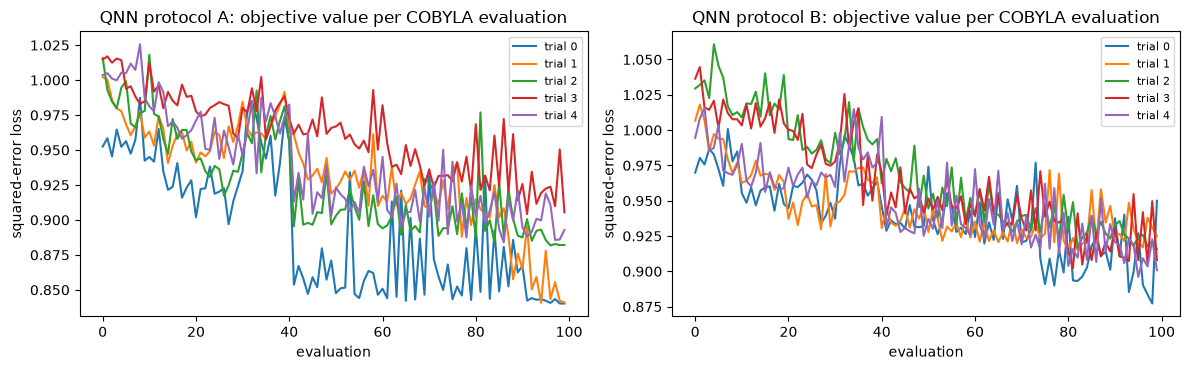

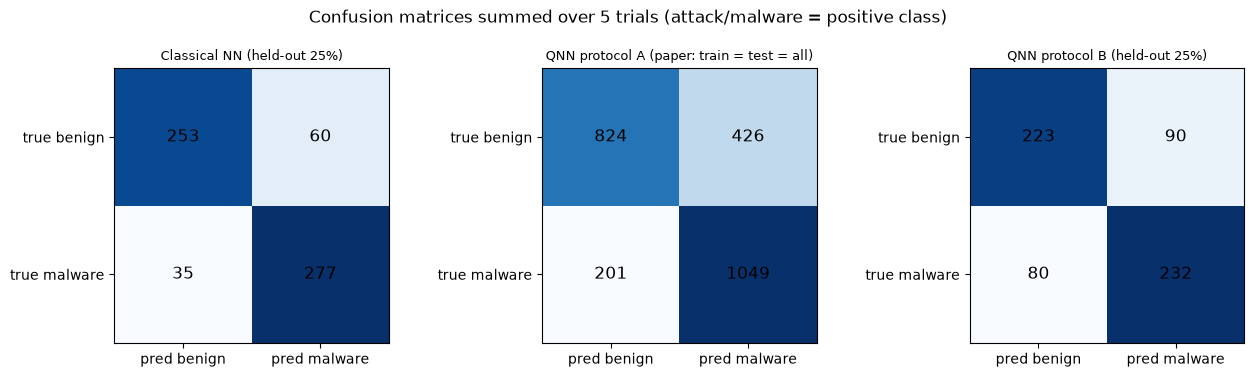

In [16]:
# live-style loss curves (recorded by the optimiser callback) for each trial
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for t, (la, lb, ln) in loss_curves.items():
    axes[0].plot(la, label=f"trial {t}"); axes[1].plot(lb, label=f"trial {t}")
axes[0].set_title("QNN protocol A: objective value per COBYLA evaluation"); axes[1].set_title("QNN protocol B: objective value per COBYLA evaluation")
for a_ in axes: a_.set_xlabel("evaluation"); a_.set_ylabel("squared-error loss"); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

# summed confusion matrices over the trials (malware = positive class)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, m in zip(axes, order[:3]):
    s_ = res[res.model == m][["tn", "fp", "fn", "tp"]].sum().values
    cm = np.array([[s_[0], s_[1]], [s_[2], s_[3]]])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): ax.text(j, i, int(v), ha="center", va="center", color="black", fontsize=12)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred benign", "pred malware"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["true benign", "true malware"])
    ax.set_title(m, fontsize=9)
fig.suptitle(f"Confusion matrices summed over {N_TRIALS} trials (attack/malware = positive class)")
plt.tight_layout(); plt.show()

### The paper's t-test (Table 1) and ours

The paper compares the five F1 scores of each network with a pooled two-sample t-test (8 degrees of freedom). First we recompute the test from the paper's own Table 1, as a check on the paper's arithmetic, then we run it on our F1 scores.

Paper Table 1 recomputed: mean 0.6928 (sd 0.2055) vs 0.6406 (sd 0.1799) | pooled t = 0.427, p = 0.6805 | Welch p = 0.6807
   (paper reports means 0.6928 / 0.6406, sd 0.2055 / 0.1799, p = 0.6805)
This notebook, classical vs QNN protocol A (paper protocol): mean 0.8549 (sd 0.0340) vs 0.7694 (sd 0.0243) | pooled t = 4.574, p = 0.0018 | Welch p = 0.0023
This notebook, classical vs QNN protocol B (held-out)   : mean 0.8549 (sd 0.0340) vs 0.7258 (sd 0.0633) | pooled t = 4.015, p = 0.0039 | Welch p = 0.0067
Null hypothesis 'equal mean F1' is rejected for protocol A at alpha = 0.05; rejected for protocol B.


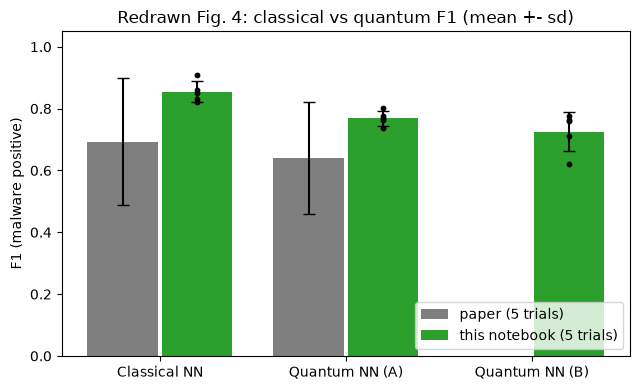

In [17]:
PAPER_T1_CLASSICAL = np.array([0.7778, 0.8, 0.3256, 0.7778, 0.7826])
PAPER_T1_QUANTUM = np.array([0.7625, 0.7646, 0.4438, 0.4438, 0.7882])
def ttest_report(a, b, label):
    st = stats.ttest_ind(a, b, equal_var=True); sw = stats.ttest_ind(a, b, equal_var=False)
    print(f"{label}: mean {a.mean():.4f} (sd {a.std(ddof=1):.4f}) vs {b.mean():.4f} (sd {b.std(ddof=1):.4f}) | "
          f"pooled t = {st.statistic:.3f}, p = {st.pvalue:.4f} | Welch p = {sw.pvalue:.4f}")
    return st.pvalue
p_paper_table = ttest_report(PAPER_T1_CLASSICAL, PAPER_T1_QUANTUM, "Paper Table 1 recomputed")
print("   (paper reports means 0.6928 / 0.6406, sd 0.2055 / 0.1799, p = 0.6805)")
f1_c = res[res.model == order[0]].sort_values("trial").f1.values
f1_qa = res[res.model == order[1]].sort_values("trial").f1.values
f1_qb = res[res.model == order[2]].sort_values("trial").f1.values
p_A = ttest_report(f1_c, f1_qa, "This notebook, classical vs QNN protocol A (paper protocol)")
p_B = ttest_report(f1_c, f1_qb, "This notebook, classical vs QNN protocol B (held-out)   ")
print("Null hypothesis 'equal mean F1' is", "supported" if p_A > 0.05 else "rejected", "for protocol A at alpha = 0.05;",
      "supported" if p_B > 0.05 else "rejected", "for protocol B.")
if N_TRIALS < 5:
    print(f"(only {N_TRIALS} trials in FAST_MODE: the test has little power)")

# redraw of Fig. 4
fig, ax = plt.subplots(figsize=(6.5, 4))
labels = ["Classical NN", "Quantum NN (A)", "Quantum NN (B)"]
ours = [f1_c, f1_qa, f1_qb]
ax.bar([0 - .2, 1 - .2], [0.6928, 0.6406], .38, yerr=[0.2055, 0.1799], capsize=4, color="tab:gray", label="paper (5 trials)")
ax.bar(np.arange(3) + .2, [x.mean() for x in ours], .38, yerr=[x.std(ddof=1) if len(x) > 1 else 0 for x in ours], capsize=4, color="tab:green", label=f"this notebook ({N_TRIALS} trials)")
for i, x in enumerate(ours): ax.scatter(np.full(len(x), i + .2), x, color="k", s=10, zorder=3)
ax.set_xticks(range(3)); ax.set_xticklabels(labels); ax.set_ylabel("F1 (malware positive)"); ax.set_ylim(0, 1.05); ax.legend(loc="lower right")
ax.set_title("Redrawn Fig. 4: classical vs quantum F1 (mean +- sd)")
plt.tight_layout(); plt.show()

## 6. Sub-problem 3: does runtime grow linearly with the number of samples? (paper Section 7.3.1, Table 2, Fig. 5)

The classical network is trained with `SCALE_EPOCHS` epochs (the paper found 150 best) on balanced samples of increasing size with a 75/25 split; the training time, prediction time and test accuracy are recorded once per size, as the paper did. Runtimes on a shared laptop CPU are not Colab runtimes, so only the *shape* of the curve is compared.

n =    100: train   36.0s, predict  0.1s, test acc 0.920


n =    200: train   25.9s, predict  0.0s, test acc 0.920


n =    500: train   24.0s, predict  0.0s, test acc 0.848


n =   1000: train   36.2s, predict  0.0s, test acc 0.796


n =   2000: train   58.7s, predict  0.0s, test acc 0.838


n =   5000: train   83.4s, predict  0.0s, test acc 0.828


n =  10000: train  132.4s, predict  0.0s, test acc 0.834


,train_s,predict_s,total_s,acc,paper_train_s,paper_test_s,paper_total_s,paper_acc
n,,,,,,,,
100,35.951,0.054,36.005,0.920,12,4,16,0.80
200,25.936,0.032,25.967,0.920,13,7,20,0.82
500,24.024,0.029,24.054,0.848,14,3,17,0.57
1000,36.181,0.032,36.213,0.796,18,6,24,0.78
2000,58.744,0.032,58.775,0.838,19,9,28,0.73
5000,83.381,0.030,83.411,0.828,44,4,48,0.76
10000,132.386,0.029,132.415,0.834,60,17,77,0.75


linear fit of training time: 10.65 s per 1,000 samples, intercept 28.1 s, R^2 = 0.973
paper's training times (same sizes): R^2 = 0.970


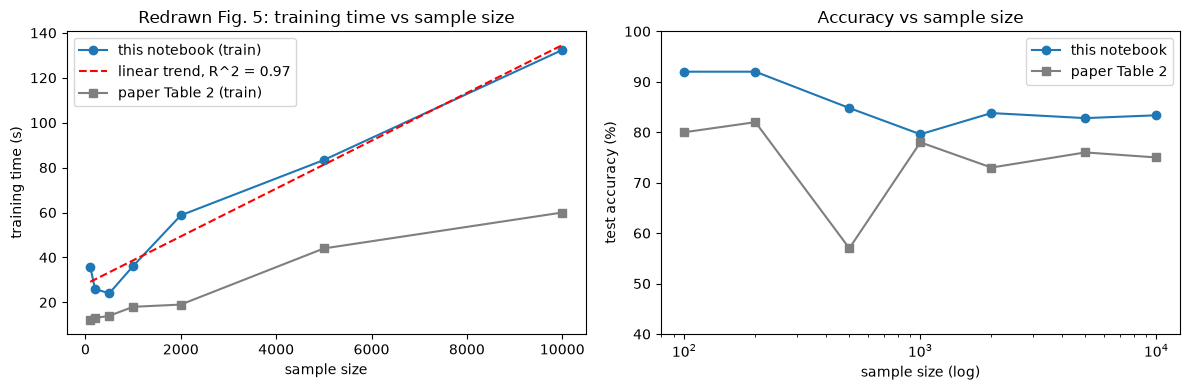

In [18]:
PAPER_T2 = pd.DataFrame({"n": [100, 200, 500, 1000, 2000, 5000, 10000], "paper_train_s": [12, 13, 14, 18, 19, 44, 60],
                         "paper_test_s": [4, 7, 3, 6, 9, 4, 17], "paper_total_s": [16, 20, 17, 24, 28, 48, 77],
                         "paper_acc": [.80, .82, .57, .78, .73, .76, .75]}).set_index("n")
srows = []
for n in SCALE_SIZES:
    tr = make_trial(0, n=n)
    feats, A_tr, A_te, p, t_fit, t_pred, loss = classical_pipeline(tr, "corr", epochs=SCALE_EPOCHS)
    srows.append(dict(n=n, train_s=t_fit, predict_s=t_pred, total_s=t_fit + t_pred, acc=accuracy_score(tr["yte"], p)))
    print(f"n = {n:6d}: train {t_fit:6.1f}s, predict {t_pred:4.1f}s, test acc {srows[-1]['acc']:.3f}")
scal = pd.DataFrame(srows).set_index("n").join(PAPER_T2)
display(scal.round(3))

xs = scal.index.values.astype(float)
slope, intercept = np.polyfit(xs, scal.train_s.values, 1)
r2 = np.corrcoef(xs, scal.train_s.values)[0, 1] ** 2
print(f"linear fit of training time: {slope * 1000:.2f} s per 1,000 samples, intercept {intercept:.1f} s, R^2 = {r2:.3f}")
pm = scal.paper_train_s.notna()
slope_p, int_p = np.polyfit(xs[pm.values], scal.paper_train_s.values[pm.values], 1)
r2_p = np.corrcoef(xs[pm.values], scal.paper_train_s.values[pm.values])[0, 1] ** 2
print(f"paper's training times (same sizes): R^2 = {r2_p:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(xs, scal.train_s, "o-", label="this notebook (train)"); axes[0].plot(xs, slope * xs + intercept, "r--", label=f"linear trend, R^2 = {r2:.2f}")
axes[0].plot(xs[pm.values], scal.paper_train_s[pm].values, "s-", color="tab:gray", label="paper Table 2 (train)")
axes[0].set_xlabel("sample size"); axes[0].set_ylabel("training time (s)"); axes[0].set_title("Redrawn Fig. 5: training time vs sample size"); axes[0].legend()
axes[1].plot(xs, scal.acc * 100, "o-", label="this notebook"); axes[1].plot(xs, scal.paper_acc * 100, "s-", color="tab:gray", label="paper Table 2")
axes[1].set_xscale("log"); axes[1].set_xlabel("sample size (log)"); axes[1].set_ylabel("test accuracy (%)"); axes[1].set_title("Accuracy vs sample size"); axes[1].legend(); axes[1].set_ylim(40, 100)
plt.tight_layout(); plt.show()

## 7. A check the paper does not make: duplicate apps

The dataset has many exact duplicate rows (the same permissions and API calls), and with only 10 binary features even *different* apps often look identical. If the same feature vector appears in both the training and the test split with the same label, it is "memorised". The cell below counts how many test rows have an identical (10-feature) twin in the training split of each trial, and how much they matter for a random forest.

In [19]:
drows = []
for tr in trials:
    feats, A_tr, A_te, *_ = cache[(tr["trial"], "corr")]
    tr_keys = {tuple(r) for r in tr["Xtr"][feats].values.astype(int)}
    te_keys = [tuple(r) for r in tr["Xte"][feats].values.astype(int)]
    twin = np.array([k in tr_keys for k in te_keys])
    rf = RandomForestClassifier(n_estimators=100, random_state=tr["seed"], n_jobs=-1).fit(A_tr, tr["ytr"])
    ok = rf.predict(A_te) == tr["yte"]
    drows.append(dict(trial=tr["trial"], test_rows=len(twin), with_identical_twin_in_train=int(twin.sum()),
                      acc_on_twins=ok[twin].mean() if twin.any() else np.nan, acc_on_unseen=ok[~twin].mean() if (~twin).any() else np.nan))
display(pd.DataFrame(drows).round(3))
distinct = data[FULL_CORR10].drop_duplicates().shape[0]
print(f"Distinct 10-feature vectors in the whole dataset: {distinct} (out of 1,024 possible) for {len(data)} apps")
print("Distinct (vector, class) pairs:", data[FULL_CORR10 + ['y']].drop_duplicates().shape[0])

,trial,test_rows,with_identical_twin_in_train,acc_on_twins,acc_on_unseen
0,0,125,121,0.843,1.000
1,1,125,110,0.845,0.867
2,2,125,121,0.802,0.750
3,3,125,116,0.879,0.778
4,4,125,121,0.901,1.000


Distinct 10-feature vectors in the whole dataset: 157 (out of 1,024 possible) for 15031 apps
Distinct (vector, class) pairs: 208


## 8. Side by side with the paper

Each claim of the paper that this notebook can test is compared below. A claim is **reproduced** when the number lies within 0.02 F1 / 2 accuracy points of the paper's (or the stated qualitative conclusion holds), **not reached** / **exceeded** otherwise, and **cannot be checked** when it depends on things outside this code (hardware, Colab timings, judges' opinions).

In [20]:
def verdict_num(paper, ours, tol):
    d = ours - paper
    if abs(d) <= tol: return "reproduced"
    return "exceeded (+%.3f)" % d if d > 0 else "not reached (%.3f)" % d

m_c, m_a, m_b = (summary.loc[order[i]] for i in range(3))
rows_v = []
def addv(claim, paper, ours, verdict): rows_v.append(dict(claim=claim, paper=paper, notebook=ours, verdict=verdict))

addv("C1a top-10 features by correlation = paper's list", "10 listed features", f"{len(set(FULL_CORR10) & set(PAPER_CORR))}/10 identical", "reproduced" if set(FULL_CORR10) == set(PAPER_CORR) else "not reached")
addv("C1b top-10 by random forest = paper's list", "10 listed features", f"{len(set(FULL_RF10) & set(PAPER_RF))}/10 overlap", "reproduced" if len(set(FULL_RF10) & set(PAPER_RF)) >= 8 else "not reached (forest ranking is seed-dependent)")
addv("C1c first-10 columns = paper's list", "10 listed features", f"{len(set(FULL_FIRST10) & set(PAPER_FIRST))}/10 identical", "reproduced" if set(FULL_FIRST10) == set(PAPER_FIRST) else "not reached")
for key, lab, pa in [("corr", "correlation set", 0.84), ("rf", "random-forest set", 0.64), ("first", "first-10 set", 0.48)]:
    o = summary_feat.loc[key, "acc_mean"]
    addv(f"C1d classical NN accuracy, {lab}", f"{pa:.2f} (1 run)", f"{o:.3f} +- {np.nan_to_num(summary_feat.loc[key, 'acc_std']):.3f} (mean of {N_TRIALS})", verdict_num(pa, o, 0.02))
gap = summary_feat.loc["corr", "acc_mean"] - summary_feat.loc[["rf", "first"], "acc_mean"].max()
addv("C1e correlation set is clearly the best of the three", "84 > 64 > 48", " / ".join(f"{summary_feat.loc[k,'acc_mean']:.2f}" for k in ["corr", "rf", "first"]),
     "reproduced" if gap >= 0.02 else f"not reached (corr set ahead by {gap:+.3f}, within noise)")
addv("C2a classical NN mean F1", "0.6928", f"{m_c.f1_mean:.4f}", verdict_num(0.6928, m_c.f1_mean, 0.02))
addv("C2b classical NN F1 sd", "0.2055", f"{m_c.f1_std:.4f}", verdict_num(0.2055, m_c.f1_std, 0.02))
addv("C2c quantum NN mean F1 (protocol A: train = test = all)", "0.6406", f"{m_a.f1_mean:.4f}", verdict_num(0.6406, m_a.f1_mean, 0.02))
addv("C2d quantum NN F1 sd (protocol A)", "0.1799", f"{m_a.f1_std:.4f}", verdict_num(0.1799, m_a.f1_std, 0.02))
addv("C2e quantum NN mean F1, held-out (protocol B, not in paper)", "n/a", f"{m_b.f1_mean:.4f}", "cannot be checked (added)")
addv("C2f Table 1 t-test arithmetic", "p = 0.6805", f"p = {p_paper_table:.4f}", verdict_num(0.6805, p_paper_table, 0.01))
addv("C2g t-test conclusion: means statistically equal (A)", "p > 0.05", f"p = {p_A:.3f}", "reproduced" if p_A > 0.05 else "not reached (means differ)")
addv("C2h classical F1 higher than quantum F1 (direction)", "0.6928 > 0.6406", f"{m_c.f1_mean:.3f} vs {m_a.f1_mean:.3f}", "reproduced" if m_c.f1_mean > m_a.f1_mean else "not reached")
addv("C3a classical NN trains in < 30 s (100 epochs)", "< 30 s", f"{m_c.fit_s:.1f} s for {EPOCHS} epochs", ("reproduced" if m_c.fit_s < 30 else "not reached") + ("" if not FAST_MODE else " (FAST_MODE epochs)"))
addv("C3b QNN needs ~30 min for 100 iterations", "~30 min", f"{m_a.fit_s:.0f} s for {QNN_MAXITER} iterations (exact batched simulator)", "cannot be checked (different simulator and CPU)")
addv("C4a runtime ~ linear in sample size", "linear trend (Fig. 5)", f"R^2 = {r2:.3f}", "reproduced" if r2 >= 0.9 else "not reached")
if 1000 in scal.index and scal.index.max() >= 2000:
    a1, a2 = scal.loc[1000, "acc"], scal.loc[scal.index.max(), "acc"]
    addv("C4b accuracy does not improve from 1,000 to the largest size", "78 % -> 75 %", f"{a1:.3f} -> {a2:.3f}", "reproduced" if a2 - a1 <= 0.02 else f"not reached (+{a2 - a1:.3f})")
acc_rng = scal.acc
addv("C4c scalability accuracies are 73-82 % (500: 57 % outlier)", "57-82 %", f"{acc_rng.min():.2f}-{acc_rng.max():.2f}", "reproduced" if (acc_rng.between(0.71, 0.84)).all() else "exceeded" if acc_rng.min() > 0.82 else "not reached")
addv("C5 usability/scalability judged suitable for small businesses", "professor feedback", "not testable in code", "cannot be checked")
verdicts = pd.DataFrame(rows_v)
pd.set_option("display.max_colwidth", 70)
display(verdicts)
print("Counts:", verdicts.verdict.str.split(" ").str[0].value_counts().to_dict())

,claim,paper,notebook,verdict
0,C1a top-10 features by correlation = paper's list,10 listed features,10/10 identical,reproduced
1,C1b top-10 by random forest = paper's list,10 listed features,6/10 overlap,not reached (forest ranking is seed-dependent)
2,C1c first-10 columns = paper's list,10 listed features,10/10 identical,reproduced
3,"C1d classical NN accuracy, correlation set",0.84 (1 run),0.848 +- 0.043 (mean of 5),reproduced
4,"C1d classical NN accuracy, random-forest set",0.64 (1 run),0.859 +- 0.056 (mean of 5),exceeded (+0.219)
5,"C1d classical NN accuracy, first-10 set",0.48 (1 run),0.819 +- 0.034 (mean of 5),exceeded (+0.339)
6,C1e correlation set is clearly the best of the three,84 > 64 > 48,0.85 / 0.86 / 0.82,"not reached (corr set ahead by -0.011, within noise)"
7,C2a classical NN mean F1,0.6928,0.8549,exceeded (+0.162)
8,C2b classical NN F1 sd,0.2055,0.0340,not reached (-0.172)
9,C2c quantum NN mean F1 (protocol A: train = test = all),0.6406,0.7694,exceeded (+0.129)


Counts: {'not': 8, 'reproduced': 6, 'exceeded': 4, 'cannot': 3}


## 9. Reading the paper critically

* **What the data say about the main question.** The paper's "statistically equal" rests on F1 spreads of 0.18-0.21 over 5 trials (its own account blames random sampling, a data-processing bug that set every label to 1, and changed split ratios). With a spread that large a t-test has almost no power, so "p = 0.68" means "this experiment cannot tell the networks apart", not "the networks are equal". In this notebook the pipeline is stable (spreads of roughly 0.02-0.06, see the table in section 5), the classical network reaches F1 of about 0.85 instead of 0.69, and the t-tests in section 5 can resolve the difference; the observations at the end of this section report the p-values of the actual run. The quantum network's F1 also rises (about 0.73-0.77 vs the paper's 0.64) but stays below the classical one.
* **The two networks are not scored the same way.** The paper trains and scores the quantum network on all 500 samples (a training score) but scores the classical network on 125 held-out samples. A training score of a model with only 40 weights is optimistic compared with a held-out score. Protocol B above removes that asymmetry.
* **Feature selection used the labels.** The "top 10 by correlation" and "top 10 by random forest" were computed on the whole dataset, which includes the apps later used for testing. That is a (mild, because the features are only ten) form of test-set leakage. Here selection is done on each trial's training split; the selected lists coincide with the paper's, so the effect is small.
* **The 84 / 64 / 48 % comparison is one run per feature set.** Differences of 20 points between single runs of a network that, by the authors' own account, varied between 15 % and 100 % across code versions and 57 % to 82 % across sample sizes are within the run-to-run noise. In this dataset the first ten columns are almost the same as the correlation set (the columns are roughly sorted by importance), so one would expect them to perform alike; averaging over trials shows what really happens.
* **Ten binary features limit everybody.** At most 1,024 distinct inputs exist, many apps share a vector (see section 7), and no classifier can separate apps that look identical but have different labels. A random forest or an SVC on the same ten inputs does about as well as the classical network (see the table in section 5), so the networks are not the bottleneck. A random forest on all 215 features is listed for reference to show how much the ten-feature restriction costs (the paper's setting is 10 qubits).
* **Quantum "simulation" is not quantum computing.** The QNN here is a classical state-vector simulation of 10 qubits; its runtime says nothing about quantum hardware. The paper rightly does not draw efficiency conclusions, but statements about quantum advantage ("quantum properties allow calculations to be performed more efficiently") are not tested by this experiment.
* **Reproducibility.** The paper does not give the layer widths, the optimiser, the exact feature-map options or the seeds, and the Colab starter code predates the current Qiskit API. The numbers here depend on those choices (marked `# CHOICE`), which is another reason to look at the spread, not the means.
* **Qualitative parts.** Usability, accessibility and "suitability for small businesses" were judged by two mentors; there is nothing to re-run.

### Observations computed from this run

In [21]:
print(f"* Classical NN held-out F1: {m_c.f1_mean:.3f} +- {m_c.f1_std:.3f}; QNN protocol A (training-set score) F1: {m_a.f1_mean:.3f} +- {m_a.f1_std:.3f}; "
      f"QNN protocol B (held-out) F1: {m_b.f1_mean:.3f} +- {m_b.f1_std:.3f}.")
rf_s, sv_s = summary.loc[order[3]], summary.loc[order[4]]
print(f"* Baselines on the same 10 inputs: random forest F1 {rf_s.f1_mean:.3f}, RBF-SVC F1 {sv_s.f1_mean:.3f}; random forest on all 215 features F1 {summary.loc[order[5]].f1_mean:.3f}.")
print(f"* Feature sets (classical NN accuracy): correlation {summary_feat.loc['corr','acc_mean']:.3f}, forest {summary_feat.loc['rf','acc_mean']:.3f}, first-10 {summary_feat.loc['first','acc_mean']:.3f}.")
print(f"* p-values (pooled t-test): protocol A {p_A:.3f}, protocol B {p_B:.3f}; paper Table 1 recomputed {p_paper_table:.3f}.")
print(f"* Training time vs sample size: linear fit R^2 = {r2:.2f} (paper's own Table 2: {r2_p:.2f}); QNN fit time per run: A {m_a.fit_s:.0f} s, B {m_b.fit_s:.0f} s for {QNN_MAXITER} COBYLA iterations.")

* Classical NN held-out F1: 0.855 +- 0.034; QNN protocol A (training-set score) F1: 0.769 +- 0.024; QNN protocol B (held-out) F1: 0.726 +- 0.063.
* Baselines on the same 10 inputs: random forest F1 0.862, RBF-SVC F1 0.854; random forest on all 215 features F1 0.939.
* Feature sets (classical NN accuracy): correlation 0.848, forest 0.859, first-10 0.819.
* p-values (pooled t-test): protocol A 0.002, protocol B 0.004; paper Table 1 recomputed 0.680.
* Training time vs sample size: linear fit R^2 = 0.97 (paper's own Table 2: 0.97); QNN fit time per run: A 258 s, B 204 s for 100 COBYLA iterations.


## 10. Exercises

1. **More trials.** Set `N_TRIALS = 30` (and `FAST_MODE = True`) and repeat the t-test between the classical network and the quantum network under protocol B. How does the p-value change, and what does that say about the paper's 5 trials?
2. **A different feature map.** Replace `zz_feature_map(..., entanglement="full")` by `entanglement="linear"` or by `z_feature_map`. Re-run the equivalence check (you will need to keep it passing) and compare protocol-B F1.
3. **Hidden widths.** The paper does not give the classical layer widths. Try `Dense(64)-Dense(32)-Dense(1)` and `Dense(4)-Dense(1)`; does the "classical beats quantum" ordering depend on this choice?
4. **Leakage.** Change `select_features` to use all rows (as the paper probably did) for the correlation ranking and compare the test accuracy with the leak-free version.
5. **More qubits or fewer.** Set `N_QUBITS = 6` or `8` (the feature-map and ansatz cells adapt) and plot test F1 against the number of features/qubits for the classical network, the QNN and a random forest. Where does the 10-qubit limit start to hurt?